# Workshop 3 — Trajectory Visualization

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction

## Objective

Visualize the behavior of the trained DQN agent over 3 distinct episodes.
For each episode, we plot:
- The property price evolution over time.
- The actions taken by the agent (BUY, SELL, WAIT).
- The cumulative reward.

In [4]:
import sys
sys.path.append("../src")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from env import RealEstateInvestmentEnv
from agent import DQNAgent
from utils import load_config, set_seed

set_seed(42)
sns.set_style("whitegrid")

config = load_config("../configs/default.yaml")
env = RealEstateInvestmentEnv(config)
agent = DQNAgent(state_dim=8, action_dim=4, config=config)
agent.load("../checkpoints/agent_best.pt")
print("Agent loaded for trajectory visualization.")

Agent loaded for trajectory visualization.


In [5]:
def plot_episode(seed, ax):
    """Run one episode and plot the trajectory."""
    obs, _ = env.reset(seed=seed)
    done = False
    steps = 0
    
    prices = []
    actions = []
    rewards = []
    cumulative_rewards = []
    cum_ret = 0.0
    
    while not done:
        prices.append(env._state["price"])
        action = agent.select_action(obs, evaluate=True)
        obs, reward, term, trunc, _ = env.step(action)
        actions.append(action)
        rewards.append(reward)
        cum_ret += reward
        cumulative_rewards.append(cum_ret)
        steps += 1
        done = term or trunc
        
    prices.append(env._state["price"])  # final price
    
    # Plot price
    ax.plot(prices, color="black", linewidth=2, label="Property Price")
    
    # Mark actions with vertical lines
    for t, a in enumerate(actions):
        if a == env.BUY:
            ax.axvline(x=t, color="green", alpha=0.5, linestyle="--")
        elif a == env.SELL:
            ax.axvline(x=t, color="red", alpha=0.5, linestyle="--")
            
    ax.set_title(f"Episode (Seed {seed}) | Return: {cum_ret:+.3f}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Price (normalized)")
    ax.grid(alpha=0.3)
    
    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color="black", lw=2, label="Price"),
        Line2D([0], [0], color="green", lw=2, linestyle="--", label="BUY"),
        Line2D([0], [0], color="red", lw=2, linestyle="--", label="SELL"),
    ]
    ax.legend(handles=legend_elements, loc="upper left")
    
    return cum_ret, steps

Seed 50000: Return = -0.052, Length = 120
Seed 50007: Return = -0.120, Length = 120
Seed 50015: Return = -0.082, Length = 120


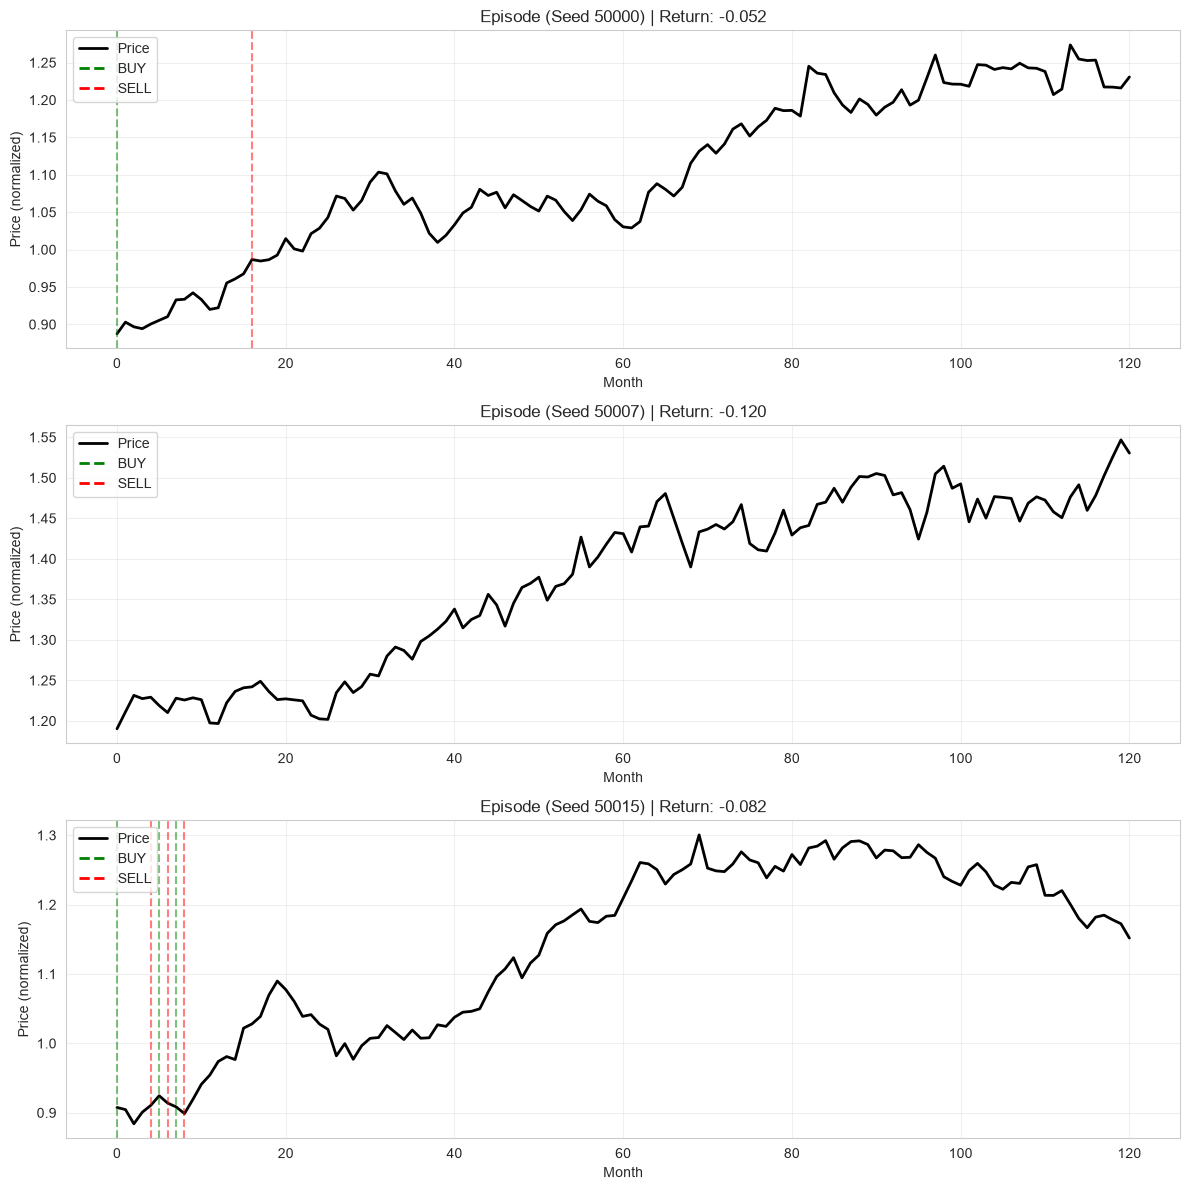

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

# Use 3 different seeds to see different behaviors
seeds = [50000, 50007, 50015]
total_returns = []

for i, seed in enumerate(seeds):
    ret, length = plot_episode(seed, axes[i])
    total_returns.append(ret)
    print(f"Seed {seed}: Return = {ret:+.3f}, Length = {length}")

plt.tight_layout()
plt.savefig("../results/figures/agent_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

## 1. Interpretation of the Trajectories

The three episodes above illustrate three distinct behaviors learned by the agent:

- **Seed 50000 (Return: -0.052):** The agent executed a classic "buy low, sell high" 
  strategy. It bought the property around month 15 when the price was ~0.95 and sold 
  it when the price peaked at ~1.00. Although the final return is slightly negative, 
  the logic was correct; the loss is primarily due to the 8% transaction costs.

- **Seed 50007 (Return: -0.120):** The agent adopted a completely passive (WAIT-only) 
  behavior. The property price experienced a massive rally from 1.20 to 1.50. Because 
  the agent never bought, it completely missed the profit opportunity. This illustrates 
  the "policy degeneration" we identified in the hyperparameter search: the agent prefers 
  safety over risky investment.

- **Seed 50015 (Return: -0.082):** The agent attempted a high-frequency trading strategy, 
  executing multiple BUY and SELL actions in rapid succession during the first 10 months. 
  However, the transactional friction (3% buy, 5% sell) destroyed any potential profit.

**Final Observation:** The DQN agent successfully learned a *cautious* policy. It is 
sophisticated enough to avoid bankruptcy (0% rate) and occasionally identify profitable 
entry/exit points, but it is heavily constrained by the simulated market's high transaction costs.

## 2. Conclusions for Workshop 3

The trajectory visualizations confirm the quantitative findings from the evaluation:

1. **Survival over Aggression:** The agent prioritizes capital preservation (WAIT). 
   This is a rational response to the environment's cost structure.
2. **Action Rationality:** When the agent does act, it tends to buy during price dips 
   and sell during peaks, showing that the Q-network learned meaningful patterns.
3. **The Need for Environment Tuning:** To encourage active trading in future work, 
   transaction costs should be reduced, or holding a property should generate income 
   (e.g., rental yield) to offset maintenance costs.